In [3]:
%matplotlib inline

import copy
import hashlib
import os
import random
from io import BytesIO
from pathlib import Path, PurePosixPath
from urllib.request import urlretrieve
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import PIL
import sklearn
import torch
from IPython.display import Markdown, display
from PIL import Image, ImageOps
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    confusion_matrix, f1_score,
)
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
HEIGHT, WIDTH = 48, 80
BATCH_SIZE = 64
EPOCHS = 14
LEARNING_RATE = 0.001
CLASS_FOLDERS = ("Bending_Damage", "Intact", "Severe_Damage")
CLASS_NAMES = ("Bending damage", "Intact", "Severe damage")
LABELS = np.arange(len(CLASS_NAMES))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print(f"Device: {device} | PyTorch: {torch.__version__}")
print(f"NumPy: {np.__version__} | Pillow: {PIL.__version__} | scikit-learn: {sklearn.__version__}")

Device: cpu | PyTorch: 2.14.1+cpu
NumPy: 2.4.6 | Pillow: 11.3.0 | scikit-learn: 1.6.1


In [4]:
ARCHIVE_URL = (
    "https://data.mendeley.com/public-files/datasets/zs55dv63kv/files/"
    "48eedb5d-3778-4b30-9894-e2851a4bf4ea/file_downloaded"
)
ARCHIVE_HASH = "32ebcdf5c36f4cf96017cfedbdc1a3218346d9695a51b41b09a886efa7871786"
ARCHIVE_BYTES = 232_155_710
archive = Path("Raw_Dataset.zip")
if not archive.exists():
    partial = archive.with_suffix(".zip.part")
    print("Downloading Raw_Dataset.zip from Mendeley Data...")
    try:
        urlretrieve(ARCHIVE_URL, partial)
    except OSError as exc:
        raise RuntimeError(
            "Download the ZIP from the Mendeley dataset record, put it beside "
            "the notebook, and rerun this cell."
        ) from exc
    partial.replace(archive)

with archive.open("rb") as file:
    checksum = hashlib.sha256()
    for block in iter(lambda: file.read(1024 * 1024), b""):
        checksum.update(block)
if archive.stat().st_size != ARCHIVE_BYTES or checksum.hexdigest() != ARCHIVE_HASH:
    raise ValueError("Archive verification failed. Replace the ZIP with the original Version 1 file.")
print(f"Verified download: {archive.stat().st_size:,} bytes (SHA-256 matched).")

class_ids = {name.casefold(): idx for idx, name in enumerate(CLASS_FOLDERS)}
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
images, targets, image_paths, source_hashes, timestamps = [], [], [], [], []
with ZipFile(archive) as dataset:
    members = [entry for entry in dataset.infolist() if not entry.is_dir()]
    for entry in sorted(members, key=lambda item: item.filename):
        path = PurePosixPath(entry.filename.replace(chr(92), "/"))
        if path.suffix.lower() not in image_extensions or "__MACOSX" in path.parts:
            continue
        label = class_ids[path.parent.name.casefold()]
        image_bytes = dataset.read(entry)
        with Image.open(BytesIO(image_bytes)) as image:
            rgb = ImageOps.exif_transpose(image).convert("RGB")
            resized = rgb.resize((WIDTH, HEIGHT), Image.Resampling.BILINEAR)
            images.append(np.array(resized))
        image_paths.append(str(path))
        source_hashes.append(hashlib.sha256(image_bytes).hexdigest())
        timestamps.append(entry.date_time)
        targets.append(label)

images = np.stack(images)
targets = np.array(targets, dtype=np.int64)
source_hashes = np.array(source_hashes)
assert images.shape == (2_400, HEIGHT, WIDTH, 3), images.shape
assert np.bincount(targets).tolist() == [800, 800, 800]
print(f"{len(images):,} decoded images from {len(CLASS_NAMES)} classes.")
print(f"Unpacked files: {sum(item.file_size for item in members):,} bytes.")
print(f"Repeated source files by exact SHA-256: {len(images) - len(set(source_hashes))}")

Verified download: 232,155,710 bytes (SHA-256 matched).
2,400 decoded images from 3 classes.
Unpacked files: 278,372,144 bytes.
Repeated source files by exact SHA-256: 0


## 2. Split the data



| Class | Train | Validation | Test | Total |
| --- | ---: | ---: | ---: | ---: |
| Bending damage | 560 | 120 | 120 | 800 |
| Intact | 564 | 117 | 119 | 800 |
| Severe damage | 562 | 119 | 119 | 800 |
| **Total** | **1686** | **356** | **358** | **2400** |

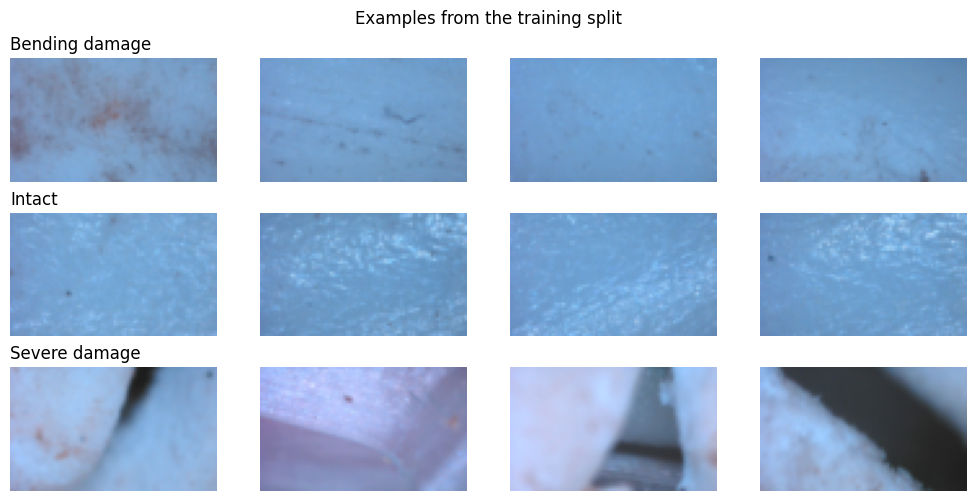

In [5]:
def keep_tied_times_together(ordered, cut):
    while 0 < cut < len(ordered) and timestamps[ordered[cut - 1]] == timestamps[ordered[cut]]:
        cut += 1
    return cut


split_lists = {"Train": [], "Validation": [], "Test": []}
for label in LABELS:
    ordered = sorted(
        np.flatnonzero(targets == label),
        key=lambda index: (timestamps[index], image_paths[index]),
    )
    val_start, val_end, test_start = [
        keep_tied_times_together(ordered, int(len(ordered) * fraction))
        for fraction in (0.40, 0.55, 0.85)
    ]
    split_lists["Train"].extend(ordered[:val_start] + ordered[val_end:test_start])
    split_lists["Validation"].extend(ordered[val_start:val_end])
    split_lists["Test"].extend(ordered[test_start:])

splits = {name: np.array(index) for name, index in split_lists.items()}
train_idx, val_idx, test_idx = splits["Train"], splits["Validation"], splits["Test"]
assert np.array_equal(np.sort(np.concatenate(list(splits.values()))), np.arange(len(targets)))
hash_sets = [set(source_hashes[group]) for group in splits.values()]
assert hash_sets[0].isdisjoint(hash_sets[1])
assert hash_sets[0].isdisjoint(hash_sets[2])
assert hash_sets[1].isdisjoint(hash_sets[2])

table = [
    "| Class | Train | Validation | Test | Total |",
    "| --- | ---: | ---: | ---: | ---: |",
]
for label, name in enumerate(CLASS_NAMES):
    counts = [np.sum(targets[split] == label) for split in splits.values()]
    table.append(f"| {name} | {counts[0]} | {counts[1]} | {counts[2]} | {sum(counts)} |")
table.append(f"| **Total** | **{len(train_idx)}** | **{len(val_idx)}** | **{len(test_idx)}** | **{len(targets)}** |")
display(Markdown("\n".join(table)))

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 4, figsize=(10, 4.9), layout="constrained")
for label, row in enumerate(axes):
    class_indices = train_idx[targets[train_idx] == label]
    for ax, index in zip(row, rng.choice(class_indices, size=4, replace=False)):
        ax.imshow(images[index])
        ax.axis("off")
    row[0].set_title(CLASS_NAMES[label], loc="left")
fig.suptitle("Examples from the training split")
plt.show()

## 3. Define the CNN



In [6]:
class CableCNN(nn.Module):
    def __init__(self, dropout_rate=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 8, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * (HEIGHT // 8) * (WIDTH // 8), 32),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(32, len(CLASS_NAMES)),
        )

    def feature_maps(self, pixels):
        first = self.conv1(pixels).relu()
        second = self.conv2(self.pool(first)).relu()
        third = self.conv3(self.pool(second)).relu()
        return first, second, third

    def forward(self, pixels):
        _, _, third = self.feature_maps(pixels)
        return self.classifier(self.pool(third))

architecture = CableCNN()
print(architecture)
print(f"Trainable parameters: {sum(p.numel() for p in architecture.parameters() if p.requires_grad):,}")

CableCNN(
  (conv1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1920, out_features=32, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=32, out_features=3, bias=True)
  )
)
Trainable parameters: 67,603


## 4. Train the baseline and regularized model



In [7]:
def make_loader(index, shuffle=False):
    pixels = torch.from_numpy(images[index]).permute(0, 3, 1, 2).contiguous()
    labels = torch.from_numpy(targets[index])
    return DataLoader(
        TensorDataset(pixels, labels), batch_size=BATCH_SIZE, shuffle=shuffle,
        generator=torch.Generator().manual_seed(SEED),
    )


train_eval_loader = make_loader(train_idx)
val_loader = make_loader(val_idx)
test_loader = make_loader(test_idx)
loss_fn = nn.CrossEntropyLoss()


def prepare_batch(pixels):
    return pixels.to(device, dtype=torch.float32).div_(255)


def flip_batch(pixels, generator):
    horizontal = torch.rand(len(pixels), 1, 1, 1, device=device, generator=generator) < 0.5
    vertical = torch.rand(len(pixels), 1, 1, 1, device=device, generator=generator) < 0.5
    pixels = torch.where(horizontal, pixels.flip(-1), pixels)
    return torch.where(vertical, pixels.flip(-2), pixels)


@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    loss_sum = 0.0
    outputs, truth = [], []
    for pixels, labels in loader:
        logits = model(prepare_batch(pixels))
        loss_sum += loss_fn(logits, labels.to(device)).item() * len(labels)
        outputs.append(logits.cpu())
        truth.append(labels)
    logits = torch.cat(outputs)
    truth = torch.cat(truth).numpy()
    predictions = logits.argmax(dim=1).numpy()
    return {
        "loss": loss_sum / len(truth),
        "accuracy": accuracy_score(truth, predictions),
        "truth": truth,
        "predictions": predictions,
        "confidence": logits.softmax(dim=1).amax(dim=1).numpy(),
    }


def fit(dropout_rate, augment):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    aug_rng = torch.Generator(device=device).manual_seed(SEED)
    model = CableCNN(dropout_rate=dropout_rate).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_loader = make_loader(train_idx, shuffle=True)
    history = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
    best_loss = float("inf")

    for epoch in range(1, EPOCHS + 1):
        model.train()
        for pixels, labels in train_loader:
            pixels, labels = prepare_batch(pixels), labels.to(device)
            if augment:
                pixels = flip_batch(pixels, aug_rng)
            optimizer.zero_grad()
            loss = loss_fn(model(pixels), labels)
            loss.backward()
            optimizer.step()

        # Score both curves on clean images in eval mode after each epoch.
        train_scores = evaluate(model, train_eval_loader)
        val_scores = evaluate(model, val_loader)
        for metric in ("loss", "accuracy"):
            history[f"train_{metric}"].append(train_scores[metric])
            history[f"val_{metric}"].append(val_scores[metric])
        if val_scores["loss"] < best_loss:
            best_loss = val_scores["loss"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
        print(
            f"{epoch:02d}/{EPOCHS} | Train loss {train_scores['loss']:.4f}, "
            f"accuracy {train_scores['accuracy']:.1%} | "
            f"Val loss {val_scores['loss']:.4f}, accuracy {val_scores['accuracy']:.1%}",
            flush=True,
        )

    model.load_state_dict(best_state)
    return {"model": model, "history": history, "epoch": best_epoch, "val_loss": best_loss}

In [8]:
print("Baseline", flush=True)
baseline = fit(dropout_rate=0.0, augment=False)
print("\nFlips + dropout", flush=True)
regularized = fit(dropout_rate=0.30, augment=True)
runs = {"Baseline": baseline, "Flips + dropout": regularized}
selected_name = min(runs, key=lambda name: runs[name]["val_loss"])
selected = runs[selected_name]
print(f"Selected by validation loss: {selected_name} (epoch {selected['epoch']})")

Baseline
01/14 | Train loss 1.0384, accuracy 57.9% | Val loss 1.0373, accuracy 56.7%
02/14 | Train loss 0.8046, accuracy 58.5% | Val loss 0.7704, accuracy 57.6%
03/14 | Train loss 0.6244, accuracy 76.1% | Val loss 0.6405, accuracy 73.0%
04/14 | Train loss 0.6162, accuracy 70.7% | Val loss 0.5100, accuracy 78.9%
05/14 | Train loss 0.5003, accuracy 78.6% | Val loss 0.4741, accuracy 79.2%
06/14 | Train loss 0.5357, accuracy 76.3% | Val loss 0.4282, accuracy 80.6%
07/14 | Train loss 0.4582, accuracy 80.5% | Val loss 0.4003, accuracy 83.1%
08/14 | Train loss 0.4335, accuracy 82.7% | Val loss 0.4086, accuracy 83.4%
09/14 | Train loss 0.4358, accuracy 82.4% | Val loss 0.4266, accuracy 80.6%
10/14 | Train loss 0.4091, accuracy 82.3% | Val loss 0.2979, accuracy 88.8%
11/14 | Train loss 0.4097, accuracy 81.7% | Val loss 0.2774, accuracy 90.4%
12/14 | Train loss 0.3488, accuracy 86.6% | Val loss 0.2815, accuracy 89.3%
13/14 | Train loss 0.3342, accuracy 86.8% | Val loss 0.2517, accuracy 90.4%
14/

## 5. Inspect the learning curves



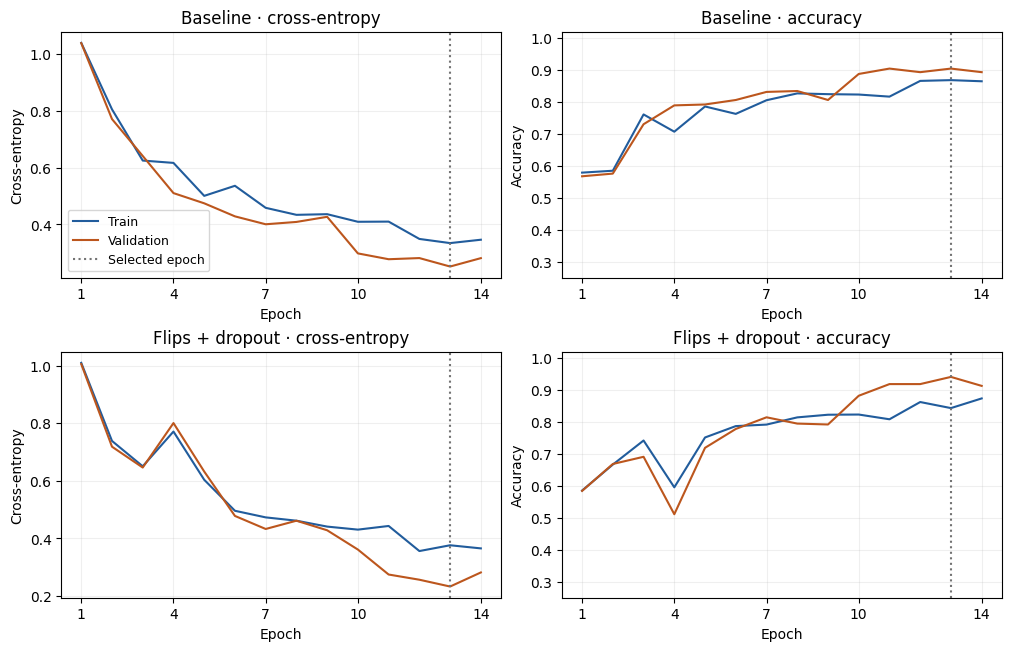

In [9]:
epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), layout="constrained")
for row, (name, run) in enumerate(runs.items()):
    for ax, metric, metric_name in zip(
        axes[row], ("loss", "accuracy"), ("cross-entropy", "accuracy"),
    ):
        ax.plot(epochs, run["history"][f"train_{metric}"], color="#215c9c", label="Train")
        ax.plot(epochs, run["history"][f"val_{metric}"], color="#bc561d", label="Validation")
        ax.axvline(run["epoch"], color="0.45", linestyle=":", label="Selected epoch")
        ax.set(title=f"{name} · {metric_name}", xlabel="Epoch", ylabel=metric_name.capitalize())
        ax.set_xticks([1, 4, 7, 10, 14])
        ax.grid(alpha=0.2)
        if metric == "accuracy":
            ax.set_ylim(0.25, 1.02)
axes[0, 0].legend(fontsize=9)
plt.show()

## 6. Evaluate on the held-out test images



| Run | Best epoch | Validation loss | Test loss | Test accuracy | Test macro F1 |
| --- | ---: | ---: | ---: | ---: | ---: |
| Baseline | 13 | 0.2517 | 0.4201 | 82.12% | 0.8215 |
| Flips + dropout | 13 | 0.2331 | 0.3786 | 86.31% | 0.8626 |

Classification report for Flips + dropout
                precision    recall  f1-score   support

Bending damage      0.764     0.892     0.823       120
        Intact      0.912     0.958     0.934       119
 Severe damage      0.946     0.739     0.830       119

      accuracy                          0.863       358
     macro avg      0.874     0.863     0.863       358
  weighted avg      0.874     0.863     0.862       358



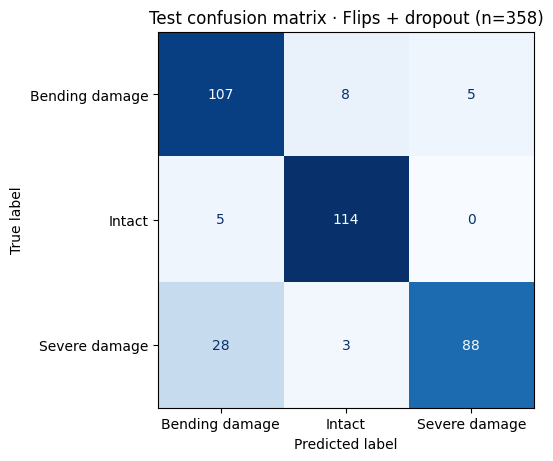

In [10]:
test_scores = {name: evaluate(run["model"], test_loader) for name, run in runs.items()}
rows = [
    "| Run | Best epoch | Validation loss | Test loss | Test accuracy | Test macro F1 |",
    "| --- | ---: | ---: | ---: | ---: | ---: |",
]
for name, run in runs.items():
    scores = test_scores[name]
    macro_f1 = f1_score(scores["truth"], scores["predictions"], labels=LABELS, average="macro")
    rows.append(
        f"| {name} | {run['epoch']} | {run['val_loss']:.4f} | {scores['loss']:.4f} | "
        f"{scores['accuracy']:.2%} | {macro_f1:.4f} |"
    )
display(Markdown("\n".join(rows)))

scores = test_scores[selected_name]
y_true, y_pred = scores["truth"], scores["predictions"]
assert np.array_equal(y_true, targets[test_idx])
print(f"Classification report for {selected_name}")
print(classification_report(y_true, y_pred, labels=LABELS, target_names=CLASS_NAMES, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=LABELS)
fig, ax = plt.subplots(figsize=(6.8, 4.5), layout="constrained")
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, colorbar=False, cmap="Blues", values_format="d",
)
ax.set_title(f"Test confusion matrix · {selected_name} (n={len(y_true)})")
plt.show()

### Inspect individual test predictions



Correct: 309 / 358 | Misclassified: 49


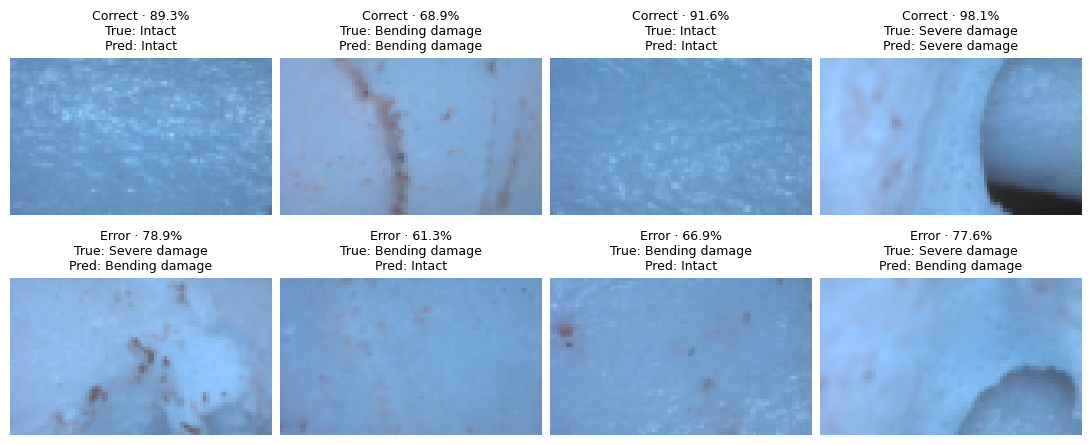

In [11]:
wrong = np.flatnonzero(y_pred != y_true)
correct = np.flatnonzero(y_pred == y_true)
print(f"Correct: {len(correct)} / {len(y_true)} | Misclassified: {len(wrong)}")
plot_rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(10.8, 4.4), layout="constrained")
for row, positions, category in zip(axes, (correct, wrong), ("Correct", "Error")):
    for ax in row:
        ax.axis("off")
    sample = plot_rng.choice(positions, size=min(4, len(positions)), replace=False)
    for ax, position in zip(row, sample):
        index = test_idx[position]
        ax.imshow(images[index])
        ax.set_title(
            f"{category} · {scores['confidence'][position]:.1%}\n"
            f"True: {CLASS_NAMES[y_true[position]]}\n"
            f"Pred: {CLASS_NAMES[y_pred[position]]}", fontsize=9,
        )
    if len(positions) == 0:
        row[0].set_title(f"No {category.lower()} samples")
plt.show()

## 7. Visualize learned filters and feature maps


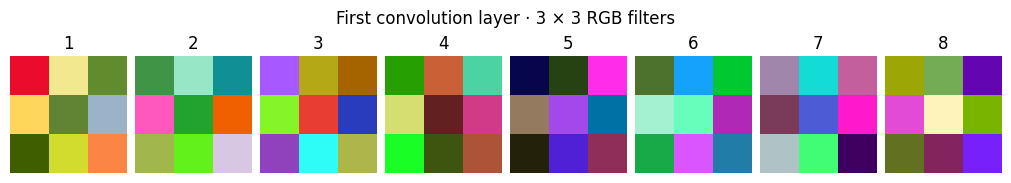

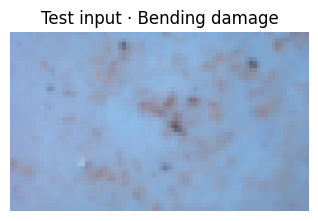

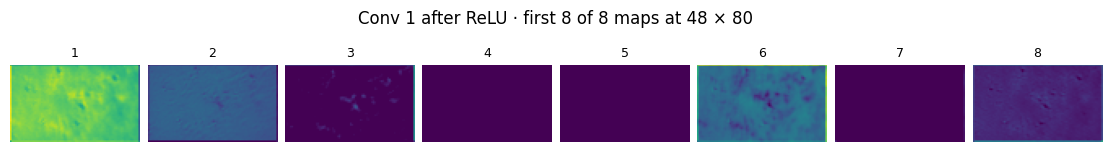

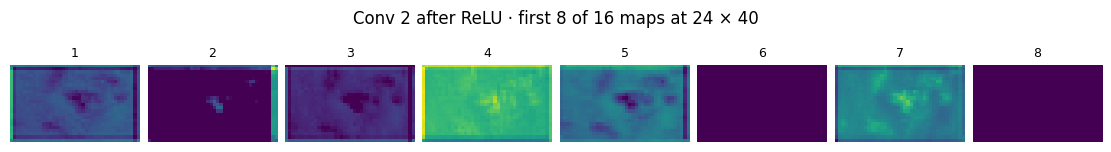

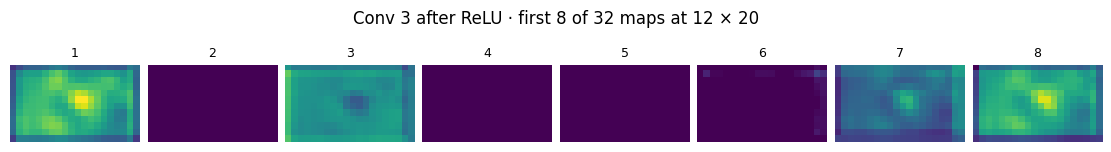

In [12]:
model = selected["model"].eval()
kernels = model.conv1.weight.detach().cpu().permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(1, len(kernels), figsize=(10, 1.9), layout="constrained")
for channel, (ax, kernel) in enumerate(zip(axes, kernels), start=1):
    normalized = (kernel - kernel.min()) / max(float(np.ptp(kernel)), 1e-8)
    ax.imshow(normalized, interpolation="nearest")
    ax.set_title(str(channel))
    ax.axis("off")
fig.suptitle("First convolution layer · 3 × 3 RGB filters")
plt.show()

example_position = int(correct[0]) if len(correct) else 0
example_index = test_idx[example_position]
example_pixels = torch.from_numpy(images[example_index]).permute(2, 0, 1).unsqueeze(0)
with torch.inference_mode():
    maps = [layer[0].cpu().numpy() for layer in model.feature_maps(prepare_batch(example_pixels))]

fig, ax = plt.subplots(figsize=(3.2, 2.1), layout="constrained")
ax.imshow(images[example_index])
ax.set_title(f"Test input · {CLASS_NAMES[targets[example_index]]}")
ax.axis("off")
plt.show()

for layer_number, layer in enumerate(maps, start=1):
    fig, axes = plt.subplots(1, 8, figsize=(11, 1.7), layout="constrained")
    for channel, ax in enumerate(axes):
        ax.imshow(layer[channel], cmap="viridis", vmin=0, vmax=max(float(layer[:8].max()), 1e-8))
        ax.axis("off")
        ax.set_title(str(channel + 1), fontsize=9)
    channels, height, width = layer.shape
    fig.suptitle(f"Conv {layer_number} after ReLU · first 8 of {channels} maps at {height} × {width}")
    plt.show()

## 8. Interpret the results



In [13]:
baseline_acc = test_scores["Baseline"]["accuracy"]
regularized_acc = test_scores["Flips + dropout"]["accuracy"]
difference_pp = 100 * (regularized_acc - baseline_acc)
other_name = "Flips + dropout" if selected_name == "Baseline" else "Baseline"
macro = f1_score(y_true, y_pred, labels=LABELS, average="macro")
recall = np.diag(cm) / cm.sum(axis=1)
weakest = int(recall.argmin())
gap_lines = []
for name, run in runs.items():
    hist = run["history"]
    final_gap = 100 * (hist["train_accuracy"][-1] - hist["val_accuracy"][-1])
    late_change = hist["val_loss"][-1] - run["val_loss"]
    gap_lines.append(
        f"- **{name}.** At epoch {EPOCHS}, the train-minus-validation accuracy gap was "
        f"**{final_gap:+.2f} percentage points**. Validation loss at the final epoch was "
        f"**{late_change:.4f}** above its minimum at epoch **{run['epoch']}**."
    )

if len(wrong):
    errors_by_pair = cm.copy()
    np.fill_diagonal(errors_by_pair, 0)
    true_label, predicted_label = np.unravel_index(errors_by_pair.argmax(), cm.shape)
    confusion_note = (
        f"The lowest test recall was **{CLASS_NAMES[weakest]} ({recall[weakest]:.1%})**. "
        f"The largest error cell was **{CLASS_NAMES[true_label]} → {CLASS_NAMES[predicted_label]}** "
        f"({cm[true_label, predicted_label]} images)."
    )
else:
    confusion_note = "All three classes had 100% recall on this test split."

display(Markdown("\n\n".join([
    f"**Final model.** Validation loss selected **{selected_name}** at epoch "
    f"**{selected['epoch']}** (loss {selected['val_loss']:.4f}, compared with "
    f"{runs[other_name]['val_loss']:.4f} for the other run). It classified "
    f"**{len(correct)} of {len(y_true)}** test images correctly "
    f"(**{scores['accuracy']:.2%}** accuracy, **{macro:.3f}** macro F1).",
    f"**Regularization comparison.** Flips + dropout changed test accuracy by "
    f"**{difference_pp:+.2f} percentage points** relative to the baseline. "
    "This comparison measures their combined effect.",
    "**Curve evidence.** A rise in validation loss after its minimum, alongside "
    "continued improvement on the training images, indicates possible "
    "overfitting. Compare both curves with the measured gaps below.",
    "\n".join(gap_lines),
    "**Error pattern.** " + confusion_note,
])))

**Final model.** Validation loss selected **Flips + dropout** at epoch **13** (loss 0.2331, compared with 0.2517 for the other run). It classified **309 of 358** test images correctly (**86.31%** accuracy, **0.863** macro F1).

**Regularization comparison.** Flips + dropout changed test accuracy by **+4.19 percentage points** relative to the baseline. This comparison measures their combined effect.

**Curve evidence.** A rise in validation loss after its minimum, alongside continued improvement on the training images, indicates possible overfitting. Compare both curves with the measured gaps below.

- **Baseline.** At epoch 14, the train-minus-validation accuracy gap was **-2.85 percentage points**. Validation loss at the final epoch was **0.0295** above its minimum at epoch **13**.
- **Flips + dropout.** At epoch 14, the train-minus-validation accuracy gap was **-3.93 percentage points**. Validation loss at the final epoch was **0.0489** above its minimum at epoch **13**.

**Error pattern.** The lowest test recall was **Severe damage (73.9%)**. The largest error cell was **Severe damage → Bending damage** (28 images).